# Growth Recursive Stochastic — Neural Net

## Setup

[JAX](https://docs.jax.dev) underlies everything below: array math via
`jax.numpy`,
[compilation](https://docs.jax.dev/en/latest/jit-compilation.html) via
`jax.jit`, and exact derivatives via [automatic
differentiation](https://docs.jax.dev/en/latest/automatic-differentiation.html)
— the solver differentiates the residual through the simulated
stochastic paths, so no derivative is coded by hand. JAX defaults to
32-bit floats, so we switch on 64-bit and the most accurate matmul
*before* creating any array.

In [1]:
import jax

jax.config.update("jax_enable_x64", True)
jax.config.update("jax_default_matmul_precision", "highest")

import math
import time

import jax.numpy as jnp
import matplotlib.pyplot as plt
from flax import nnx
from nlls_gram import LevenbergMarquardt
from tinydiffeq import EulerMaruyama, SaveAt, solve_sde

Structural parameters: the sequential calibration of the growth model
plus an Ornstein–Uhlenbeck process for log TFP. The dict `p` is the
solver’s differentiable-parameter pytree.

In [2]:
a = 1.0 / 3.0  # capital share in f(z, k) = z k^a
delta = 0.1  # depreciation rate
rho_hat = -4.0 * math.log(0.9896)  # continuous discount rate (quarterly beta anchor)
sigma_crra = 2.0  # CRRA curvature
# OU log TFP: d log z = eta (log z_bar - log z) dt + sigma_z dW, matched to a
# quarterly AR(1) with persistence 0.95 and innovation sd 0.035.
eta = -4.0 * math.log(0.95)
sigma_z = math.sqrt(2.0 * eta * 0.035**2 / (1.0 - 0.95**2))
log_z_bar = 0.0
z_0 = 1.0  # initial TFP
k_0 = 1.0  # initial capital
p = {
    "a": a,
    "delta": delta,
    "rho_hat": rho_hat,
    "sigma_crra": sigma_crra,
    "eta": eta,
    "sigma_z": sigma_z,
    "log_z_bar": log_z_bar,
}

Parameters of the algorithm. Two seeds: one for the network
initialization and one for the Brownian paths, split up front into
independent training, test, and transversality streams so that changing
the network seed leaves every path fixed.

In [3]:
WIDTH = 16
DEPTH = 2  # hidden silu layers
HEAD_INIT_SCALE = 1e-3  # near-zero head: the policy starts at the anchor
SEED = 0  # network initialization
DATA_SEED = 0  # Brownian paths: training epochs, test, transversality
TRAIN_T = 60.0
TRAIN_STEPS = 40  # Euler-Maruyama steps; residuals sit on the 41 states per path
TRAIN_PATHS = 16  # Brownian paths from the single initial state
TEST_T = 40.0
TEST_STEPS = 40
TEST_PATHS = 50
TVC_T = 200.0
TVC_STEPS = 256
EPOCHS = 4  # each epoch redraws the Brownian paths
STEPS_PER_EPOCH = 125
LOSS_THRESHOLD = 5e-13  # mean squared Euler residual on a fresh batch
INIT_DAMPING = 3.26e-5
DAMPING_DECREASE = 0.482
DAMPING_INCREASE = 2.71
GEODESIC_ACCEPTANCE_RATIO = 0.541

## The mathematical problem

The unknowns are functions of the state $x = (\log z, \log k)$ rather
than paths in time, and subscripts $z$ below denote derivatives with
respect to the coordinate $\log z$. Relative to the paper’s notation,
its $z$ is $\log z$ here, and its $(\gamma, \sigma, \kappa, r)$ are
$(\sigma, \sigma_z, \eta, \hat\rho)$. Given an investment policy $i(x)$,
consumption clears the resource constraint, $c(x) = z k^a - i(x)$, and
the state follows the SDE

$$
d \log z = \eta\,(\log \bar z - \log z)\, dt + \sigma_z\, dW,
\qquad
d \log k = \Big(\frac{i(x)}{k} - \delta\Big) dt,
$$

with $W$ a scalar Brownian motion, so the volatility vector is
$B = (\sigma_z, 0)^\top$. With $\mathcal{L}$ the generator of this
diffusion, optimality is the co-state equation for the marginal utility
$\mu(x) = c(x)^{-\sigma}$,

$$
\hat\rho\, \mu = \mu\,\big(a z k^{a-1} - \delta\big) + \mathcal{L}\mu .
$$

Substituting $\mu = e^{-\sigma \ell}$ with $\ell = \log c$, expanding
$\mathcal{L}\mu$, and dividing by $-\sigma\mu$ gives the stochastic
Euler equation whose residual the code enforces,

$$
R(x; i) := \nabla \ell \cdot F + \frac{\sigma_z^2}{2}\big(\ell_{zz} - \sigma\, \ell_z^2\big) - \frac{1}{\sigma}\big(a z k^{a-1} - \delta - \hat\rho\big),
$$

where $F$ is the drift of the SDE above and the second term is the Itô
correction from the volatility of $\log z$. With $\sigma_z = 0$ this is
exactly the deterministic Euler residual. The transversality condition
is
$\lim_{t\to\infty} \mathbb{E}\big[e^{-\hat\rho t}\, k(t)\, \mu(x(t)) \,\big|\, x_0\big] = 0$
and, as in the sequential problems, it is never imposed: the inductive
bias of the approximation is relied on to select the saddle path.

A global solution would drive $\sup_x |R(x; i)|$ to zero. Instead we
apply the paper’s *adaptive* risk-minimization problem to this
normalized residual, with the distribution of states induced by the
policy itself. With $\mathbb{W}_T$ the Wiener measure on $[0, T]$ and a
point-mass initial condition $x_0$,

$$
\min_{i}\; \mathbb{E}_{W \sim \mathbb{W}_T}\Big[\frac{1}{T}\int_0^T R\big(x(t); i\big)^2\, dt\Big]
\quad\text{s.t.}\quad x(t) \text{ solves the SDE from } x_0 \text{ under } i .
$$

The expectation is over randomness independent of the unknown policy.

## The sample average approximation

Hold a finite set of Brownian paths fixed and replace the expectation by
an average. With $t_j = (j-1)\Delta t$, $\Delta t = T/(N-1)$, draw
increments $\Delta W_j^{(s)} = \sqrt{\Delta t}\, Z_j^{(s)}$,
$Z_j^{(s)} \sim \mathcal{N}(0, 1)$, for paths $s = 1, \ldots, S$, and
discretize the SDE by Euler–Maruyama from $\hat x_1^{(s)} = x_0$,

$$
\hat x_{j+1}^{(s)} = \hat x_j^{(s)} + \Delta t\, F\big(\hat x_j^{(s)}; \theta\big) + B\, \Delta W_j^{(s)} .
$$

The SAA problem over the network parameters $\theta$ is then

$$
\min_\theta\; \frac{1}{SN} \sum_{s=1}^{S} \sum_{j=1}^{N} R\big(\hat x_j^{(s)}; \theta\big)^2 ,
$$

where every state $\hat x_j^{(s)}$ is itself a differentiable function
of $\theta$ through the recursion, and the gradient passes through it.
The draws are renewed each epoch, which reduces dependence on any one
noise sample without needing a large $S$ in a single step.

## The hypothesis class

The policy is a small MLP of the log state, centered at
$x_c = (\log \bar z, \log k_0)$, whose scalar head passes through the
normalized softplus $U$ (with $U(0) = U'(0) = 1$) and multiplies the
replacement-investment anchor,

$$
i(x) = \delta\, k_0\; U\!\big(h_\theta(x - x_c)\big),
$$

so a near-zero head initializes at exact replacement investment at the
initial capital. No steady-state or benchmark information enters the
map.

In [4]:
def unit_softplus(raw):
    return jax.nn.softplus(2.0 * jnp.log(2.0) * raw) / jnp.log(2.0)


log_state_0 = jnp.array([log_z_bar, math.log(k_0)])
log_state_initial = jnp.array([math.log(z_0), math.log(k_0)])


class InvestmentPolicy(nnx.Module):
    def __init__(self, *, rngs: nnx.Rngs):
        layers = [nnx.Linear(2, WIDTH, param_dtype=jnp.float64, rngs=rngs)]
        for _ in range(DEPTH - 1):
            layers.append(nnx.Linear(WIDTH, WIDTH, param_dtype=jnp.float64, rngs=rngs))
        self.layers = nnx.List(layers)
        self.head = nnx.Linear(
            WIDTH,
            1,
            kernel_init=nnx.initializers.normal(HEAD_INIT_SCALE),
            param_dtype=jnp.float64,
            rngs=rngs,
        )

    def __call__(self, log_state):
        h = log_state - log_state_0
        for layer in self.layers:
            h = jax.nn.silu(layer(h))
        return delta * k_0 * unit_softplus(self.head(h))

## Model functions and simulation

The residual needs $\nabla\ell \cdot F$, $\ell_z$, and $\ell_{zz}$. All
three are forward-mode derivatives of $\ell(x) = \log c(x)$: one
[`jax.jvp`](https://docs.jax.dev/en/latest/automatic-differentiation.html)
along the drift, and a `jax.jvp` of a `jax.jvp` in the $z$ direction for
the second derivative. Paths come from
[`tinydiffeq`](https://github.com/HighDimensionalEconLab/tinydiffeq)’s
fixed-step `solve_sde`: a PRNG key fixes the Brownian increments of one
path, the policy is closed over, and the integrator’s own states are
saved, so training differentiates straight through the simulation.
`jax.vmap` maps one path to many and one state to all the states on a
path.

In [5]:
def consumption(policy, log_state, p):
    z, k = jnp.exp(log_state)
    return z * k ** p["a"] - policy(log_state)[0]


def log_state_drift(policy, log_state, p):
    log_z, log_k = log_state
    return jnp.stack(
        [
            p["eta"] * (p["log_z_bar"] - log_z),
            policy(log_state)[0] / jnp.exp(log_k) - p["delta"],
        ]
    )


def log_state_diffusion(log_state, p):
    return jnp.stack([p["sigma_z"], 0.0])


def euler_residual(policy, log_state, p):
    def log_consumption(state):
        return jnp.log(consumption(policy, state, p))

    e_z = jnp.array([1.0, 0.0])
    drift = log_state_drift(policy, log_state, p)
    log_c, dlog_c_dt = jax.jvp(log_consumption, (log_state,), (drift,))
    l_z, l_zz = jax.jvp(
        lambda state: jax.jvp(log_consumption, (state,), (e_z,))[1],
        (log_state,),
        (e_z,),
    )
    z, k = jnp.exp(log_state)
    # 0 * log_c is NaN where c <= 0; the tangents alone would stay finite there.
    return (
        dlog_c_dt
        + 0.5 * p["sigma_z"] ** 2 * (l_zz - p["sigma_crra"] * l_z**2)
        + 0.0 * log_c
        - (p["a"] * z * k ** (p["a"] - 1.0) - p["delta"] - p["rho_hat"])
        / p["sigma_crra"]
    )


def simulate(policy, key, T, n_steps, p):
    return solve_sde(
        lambda log_state: log_state_drift(policy, log_state, p),
        lambda log_state: log_state_diffusion(log_state, p),
        EulerMaruyama(),
        0.0,
        T,
        log_state_initial,
        key=key,
        n_steps=n_steps,
        save_at=SaveAt(steps=True),
    )


def euler_residuals_on_paths(policy, keys, T, n_steps, p):
    solution = jax.vmap(lambda key: simulate(policy, key, T, n_steps, p))(keys)
    return jax.vmap(jax.vmap(lambda s: euler_residual(policy, s, p)))(solution.xs)

## The SAA solve

The residual vector holds $R/\sqrt{SN}$ at each simulated state, so its
squared norm is the SAA objective. The Brownian paths of the batch ride
in `args` as PRNG keys. Each epoch splits a fresh batch key and
evaluates the loss on that fresh batch: training stops early if it is
already under `LOSS_THRESHOLD`, and otherwise
[`nlls-gram`](https://pypi.org/project/nlls-gram/)’s Levenberg–Marquardt
runs on the batch from the current parameters until the epoch’s step
budget.

In [6]:
graphdef, theta_0 = nnx.split(InvestmentPolicy(rngs=nnx.Rngs(SEED)), nnx.Param)


# Jitted because the solver also evaluates it eagerly once per solve to size buffers.
@jax.jit
def residual_fn(theta, args, p):
    policy = nnx.merge(args["graphdef"], theta)
    euler = euler_residuals_on_paths(policy, args["keys"], TRAIN_T, TRAIN_STEPS, p)
    return (euler / jnp.sqrt(euler.size)).reshape(-1)


@jax.jit
def loss(theta, args, p):
    return jnp.sum(residual_fn(theta, args, p) ** 2)


solver = LevenbergMarquardt(
    residual_fn,
    init_damping=INIT_DAMPING,
    damping_decrease=DAMPING_DECREASE,
    damping_increase=DAMPING_INCREASE,
    geodesic_acceptance_ratio=GEODESIC_ACCEPTANCE_RATIO,
)
theta = theta_0
epoch_key, test_key, tvc_key = jax.random.split(jax.random.key(DATA_SEED), 3)
total_steps = 0
start = time.perf_counter()
for epoch in range(EPOCHS):
    epoch_key, batch_key = jax.random.split(epoch_key)
    args = {"graphdef": graphdef, "keys": jax.random.split(batch_key, TRAIN_PATHS)}
    fresh_loss = float(loss(theta, args, p))
    print(f"epoch {epoch}: fresh-batch loss {fresh_loss:.3e}")
    if fresh_loss < LOSS_THRESHOLD:
        break
    result = solver.solve(theta, args, p=p, max_steps=STEPS_PER_EPOCH)
    theta = result.x
    total_steps += int(result.steps)
solve_time = time.perf_counter() - start
policy = nnx.merge(graphdef, theta)

epoch 0: fresh-batch loss 1.100e-02
epoch 1: fresh-batch loss 6.901e-12
epoch 2: fresh-batch loss 2.410e-13

## Results

There is no closed-form benchmark, so the test is the Euler residual
itself on held-out Brownian paths from the same initial condition over a
fresh horizon. The finite-horizon transversality diagnostic simulates to
$T = 200$ on each of many paths and evaluates the log of
$e^{-\hat\rho T} c(T)^{-\sigma} k(T)$, normalized by its initial-date
value, reporting the maximum over paths: a capital bubble drives it up,
while on the saddle path every sampled realization sits far negative.

In [7]:
test_keys = jax.random.split(test_key, TEST_PATHS)
test_solution = jax.vmap(lambda key: simulate(policy, key, TEST_T, TEST_STEPS, p))(
    test_keys
)
euler_test = jax.vmap(jax.vmap(lambda s: euler_residual(policy, s, p)))(
    test_solution.xs
)

terminal_log_states = jax.vmap(
    lambda key: simulate(policy, key, TVC_T, TVC_STEPS, p).xs[-1]
)(jax.random.split(tvc_key, TEST_PATHS))
c_T = jax.vmap(lambda s: consumption(policy, s, p))(terminal_log_states)
c_init = consumption(policy, log_state_initial, p)
log_tvc = (-rho_hat * TVC_T - sigma_crra * jnp.log(c_T) + terminal_log_states[:, 1]) - (
    -sigma_crra * jnp.log(c_init) + math.log(k_0)
)

print(f"solve: {total_steps} steps in {solve_time:.2f}s (incl. jit)")
print(
    f"test |Euler residual| over {TEST_PATHS} fresh paths: "
    f"mean {float(jnp.abs(euler_test).mean()):.3e}, max {float(jnp.abs(euler_test).max()):.3e}"
)
print(f"max log-TVC at t={TVC_T:.0f} over {TEST_PATHS} paths: {float(log_tvc.max()):.1f}   (should be << 0)")

solve: 250 steps in 6.11s (incl. jit)
test |Euler residual| over 50 fresh paths: mean 7.614e-08, max 2.472e-05
max log-TVC at t=200 over 50 paths: -8.0   (should be << 0)

The 50 held-out paths fan out from the common initial condition: TFP
wanders around $\bar z$, capital rises and then fluctuates across paths,
and the Euler residuals remain small throughout.

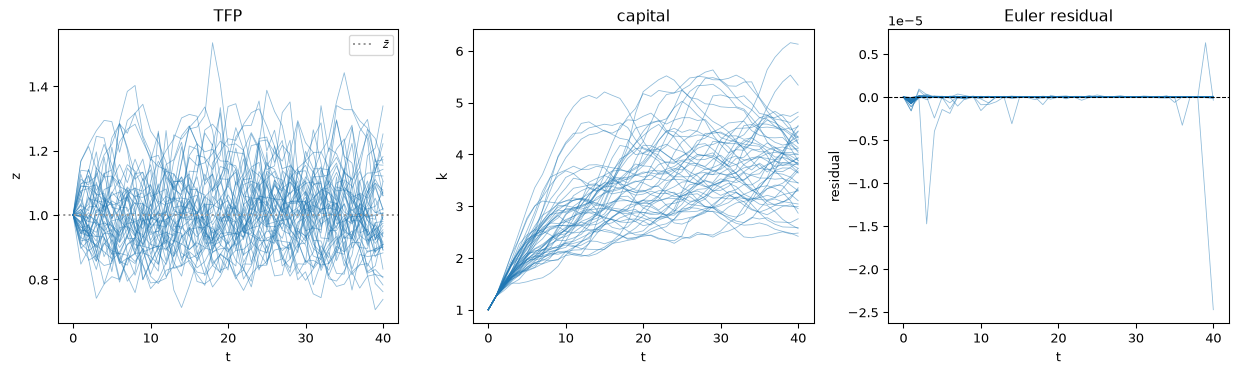

In [8]:
ts = test_solution.ts[0]
z_test, k_test = jnp.moveaxis(jnp.exp(test_solution.xs), -1, 0)

fig, (ax_z, ax_k, ax_r) = plt.subplots(1, 3, figsize=(13, 4))
ax_z.plot(ts, z_test.T, "C0", linewidth=0.6, alpha=0.5)
ax_z.axhline(math.exp(log_z_bar), color="0.6", linestyle=":", label=r"$\bar z$")
ax_z.set(xlabel="t", ylabel="z", title="TFP")
ax_z.legend(fontsize=8)
ax_k.plot(ts, k_test.T, "C0", linewidth=0.6, alpha=0.5)
ax_k.set(xlabel="t", ylabel="k", title="capital")
ax_r.plot(ts, euler_test.T, "C0", linewidth=0.6, alpha=0.5)
ax_r.axhline(0.0, color="k", linestyle="--", linewidth=0.8)
ax_r.set(xlabel="t", ylabel="residual", title="Euler residual")
fig.tight_layout()
plt.show()